# 02 — Results tables and learning curves

Reads the finished training and evaluation runs under `results/` and builds every results
table: learning curves, the validation table, and the final test / held-out tables with the
hypothesis verdicts. Nothing is simulated here, so the notebook can be re-run at any time
without touching the test or held-out flows.

Outputs: `docs/figures/training/learning_curves.png` and `docs/results/*.csv`
(`val_phase6`, `test_{main,ablation,robustness,efficiency,safety_explain}`,
`heldout_generalisation`, `heldout_generalisation_all`). The report's tables and numbers
are taken from these CSV files.

Run: `jupyter nbconvert --to notebook --execute --inplace notebooks/02_results.ipynb`
(from the repo root; needs `results/train/`, `results/eval/` and `results/final/`).

In [1]:
import json
from collections.abc import Mapping, Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from trafficrl.data.splits import REPO_ROOT
from trafficrl.eval import hypotheses as hyp
from trafficrl.eval.report import condition_name, finished_run, fmt
from trafficrl.utils.config import read_yaml
from trafficrl.utils.plotting import (
    CONTROLLER_COLOR, CONTROLLER_LABEL, INK_SECONDARY, apply_style, save_figure,
)
from trafficrl.utils.stats import summarise, t975

TRAIN_DIR = REPO_ROOT / "results" / "train"
EVAL_DIR = REPO_ROOT / "results" / "eval"
FINAL_DIR = REPO_ROOT / "results" / "final"
OUT_DIR = REPO_ROOT / "docs" / "results"
VAL_TABLE = OUT_DIR / "val_phase6.csv"
TAG = "final"
SEEDS = [0, 1, 2, 3, 4]
apply_style()

### Reading the saved runs

Small helpers that collect the per-seed `metrics.csv`, `summary.json` and `val_log.csv`
files of finished runs.

In [2]:
def latest_eval_run(eval_dir: Path, agent: str, dataset: str, split: str) -> Path:
    """Most recent ``results/eval/<agent>_<dataset>-<split>_clean_<stamp>`` directory."""
    runs = sorted(eval_dir.glob(f"{agent}_{dataset}-{split}_clean_*"))
    if not runs:
        raise FileNotFoundError(f"no clean {dataset}/{split} evaluation of {agent} in {eval_dir}")
    return runs[-1]


def training_summaries(train_dir: Path, agent: str, tag: str, seeds: Sequence[int]) -> pd.DataFrame:
    rows = []
    for s in seeds:
        f = train_dir / f"{agent}_{tag}_s{s}" / "summary.json"
        if f.exists():
            rows.append(json.loads(f.read_text()))
    return pd.DataFrame(rows)


def val_curves(train_dir: Path, agent: str, tag: str, seeds: Sequence[int]) -> pd.DataFrame:
    """Per training episode: mean, 95 % CI (Student t) and n of the val travel time over seeds."""
    frames = []
    for s in seeds:
        f = train_dir / f"{agent}_{tag}_s{s}" / "val_log.csv"
        if f.exists():
            df = pd.read_csv(f)[["episode", "avg_travel_time_s"]]
            frames.append(df.assign(seed=s))
    if not frames:
        raise FileNotFoundError(f"no val logs for {agent}_{tag}_s* in {train_dir}")
    allv = pd.concat(frames)
    rows = []
    for ep, g in allv.groupby("episode"):
        v = g["avg_travel_time_s"].to_numpy(float)
        n = len(v)
        sd = float(v.std(ddof=1)) if n > 1 else 0.0
        half = t975(n - 1) * sd / np.sqrt(n) if n > 1 else 0.0
        rows.append(
            {
                "episode": int(ep),
                "mean": v.mean(),
                "std": sd,
                "ci95_low": v.mean() - half,
                "ci95_high": v.mean() + half,
                "n": n,
            }
        )
    return pd.DataFrame(rows)


def metric_stats(metrics_csv: Path, metric: str) -> dict:
    return summarise(pd.read_csv(metrics_csv)[metric].tolist())


def study_runs(spec: Mapping, study_dir: Path) -> dict[tuple[str, str], Path | None]:
    """``{(model, condition): run directory or None}`` in the spec's table order."""
    return {
        (model, condition_name(dict(c or {}))): finished_run(
            Path(study_dir) / "eval" / f"{model}__{condition_name(dict(c or {}))}"
        )
        for model in spec["models"]
        for c in spec["conditions"]
    }


def load_study(spec: Mapping, study_dir: Path) -> pd.DataFrame:
    """Per-seed metrics of every finished job: ``model, condition, run_dir, seed, <metrics>``."""
    frames, absent = [], []
    for (model, cond), run in study_runs(spec, study_dir).items():
        if run is None:
            absent.append(f"{model}__{cond}")
            continue
        m = pd.read_csv(run / "metrics.csv")
        m.insert(0, "run_dir", str(run))
        m.insert(0, "condition", cond)
        m.insert(0, "model", model)
        frames.append(m)
    if absent:
        raise FileNotFoundError(f"no finished run for {absent} in {study_dir}")
    return pd.concat(frames, ignore_index=True)

## 1. Learning curves

Greedy validation travel time (Jinan `real_2000`) every 5 training episodes: mean over the
five training seeds with a 95 % CI band (Student t); Fixed-Time and Max-Pressure on the same
flow as dashed reference lines. Left: all evaluations; right: from episode 30, y axis cut.

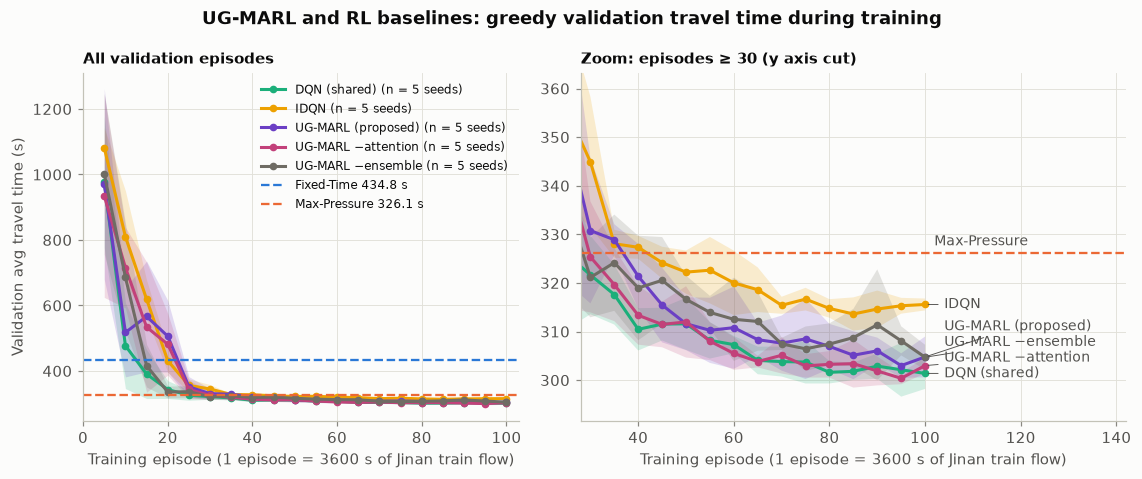

DQN (shared): best mean 301.4 s at episode 100, last 301.4 s
IDQN: best mean 313.6 s at episode 85, last 315.6 s
UG-MARL (proposed): best mean 303.0 s at episode 95, last 304.8 s
UG-MARL −attention: best mean 300.4 s at episode 95, last 303.0 s
UG-MARL −ensemble: best mean 304.7 s at episode 100, last 304.7 s
Fixed-Time: 434.8 s (deterministic)
Max-Pressure: 326.1 s (deterministic)


In [3]:
LEARNED = ["dqn", "idqn", "ugmarl", "ugmarl-noattn", "ugmarl-noens"]

fig, (ax_full, ax_zoom) = plt.subplots(
    1, 2, figsize=(10.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]}
)
curves = {a: val_curves(TRAIN_DIR, a, TAG, SEEDS) for a in LEARNED}
rules = {}
for rule in ("fixed_time", "max_pressure"):
    run = latest_eval_run(EVAL_DIR, rule, "jinan", "val")
    rules[rule] = metric_stats(run / "metrics.csv", "avg_travel_time_s")["mean"]
episodes_max = max(int(c["episode"].max()) for c in curves.values())
summary = []
labels: list[tuple[float, float, str]] = []
for agent, c in curves.items():
    color = CONTROLLER_COLOR[agent]
    for ax in (ax_full, ax_zoom):
        ax.fill_between(
            c["episode"], c["ci95_low"], c["ci95_high"], color=color, alpha=0.18, linewidth=0
        )
        ax.plot(
            c["episode"],
            c["mean"],
            color=color,
            linewidth=2,
            marker="o",
            markersize=4,
            label=f"{CONTROLLER_LABEL[agent]} (n = {int(c['n'].iloc[-1])} seeds)",
        )
    last = c.iloc[-1]
    labels.append((float(last["mean"]), float(last["episode"]), CONTROLLER_LABEL[agent]))
    best = c.loc[c["mean"].idxmin()]
    summary.append(
        f"{CONTROLLER_LABEL[agent]}: best mean {best['mean']:.1f} s at episode "
        f"{int(best['episode'])}, last {last['mean']:.1f} s"
    )
for rule, v in rules.items():
    for ax in (ax_full, ax_zoom):
        ax.axhline(
            v,
            color=CONTROLLER_COLOR[rule],
            linestyle="--",
            linewidth=1.5,
            label=f"{CONTROLLER_LABEL[rule]} {v:.1f} s" if ax is ax_full else None,
        )
    summary.append(f"{CONTROLLER_LABEL[rule]}: {v:.1f} s (deterministic)")

z0 = 30
lo = min(c.loc[c["episode"] >= z0, "ci95_low"].min() for c in curves.values())
hi = max(c.loc[c["episode"] >= z0, "ci95_high"].max() for c in curves.values())
lo, hi = min(lo, rules["max_pressure"]), max(hi, rules["max_pressure"])
pad = 0.08 * (hi - lo)
ax_zoom.set_xlim(z0 - 2, episodes_max * 1.42)
ax_zoom.set_ylim(lo - pad, hi + pad)
gap = 0.045 * (hi - lo + 2 * pad)
placed: list[float] = []
for y, x, text in sorted(labels):
    y_lab = max(y, placed[-1] + gap) if placed else y
    placed.append(y_lab)
    ax_zoom.annotate(
        text,
        (x, y),
        xytext=(x + 0.04 * episodes_max, y_lab),
        textcoords="data",
        va="center",
        color=INK_SECONDARY,
        fontsize=9,
        arrowprops={"arrowstyle": "-", "color": INK_SECONDARY, "lw": 0.6},
    )
ax_zoom.annotate(
    CONTROLLER_LABEL["max_pressure"],
    (episodes_max, rules["max_pressure"]),
    xytext=(6, 3),
    textcoords="offset points",
    va="bottom",
    color=INK_SECONDARY,
    fontsize=9,
)
ax_full.set_xlim(0, episodes_max + 3)
ax_full.legend(loc="upper right", fontsize=8, frameon=False)
ax_full.set_title("All validation episodes", fontsize=10)
ax_zoom.set_title(f"Zoom: episodes ≥ {z0} (y axis cut)", fontsize=10)
for ax in (ax_full, ax_zoom):
    ax.set_xlabel("Training episode (1 episode = 3600 s of Jinan train flow)")
ax_full.set_ylabel("Validation avg travel time (s)")
fig.suptitle("UG-MARL and RL baselines: greedy validation travel time during training",
             fontweight="bold")
fig.tight_layout()
save_figure(fig, REPO_ROOT / "docs" / "figures" / "training" / "learning_curves.png")
plt.show()
print("\n".join(summary))

## 2. Validation results

Every model on the Jinan validation flow, clean detectors. A learned agent's seed s is
evaluated with the checkpoint trained with seed s. Validation was also used for checkpoint,
hyperparameter and τ selection, so the learned agents' scores here are optimistic.

In [4]:
METRICS = [
    ("avg_travel_time_s", "Avg travel time (s)"),
    ("avg_waiting_time_s", "Avg waiting time (s)"),
    ("max_waiting_time_s", "Max per-vehicle wait (s)"),
    ("throughput_veh", "Throughput (veh)"),
    ("fallback_rate", "Fallback rate"),
    ("decision_latency_ms", "Decision latency (ms)"),
]


RULES = ("fixed_time", "max_pressure")


def training_model(model: str) -> str:
    """Training runs behind a model: −gate re-uses the full model's checkpoints."""
    return "ugmarl" if model == "ugmarl-nogate" else model


VAL_MODELS = ["fixed_time", "max_pressure", "dqn", "idqn", "ugmarl", "ugmarl-nogate",
              "ugmarl-noattn", "ugmarl-noens"]

rows, md_rows = [], []
for agent in VAL_MODELS:
    run = latest_eval_run(EVAL_DIR, agent, "jinan", "val")
    mcsv = run / "metrics.csv"
    seeds = pd.read_csv(mcsv)["seed"].tolist()
    row = {"model": agent, "eval_run": run.name, "seeds": " ".join(map(str, seeds))}
    md = [CONTROLLER_LABEL.get(agent, agent)]
    for key, _ in METRICS:
        st = metric_stats(mcsv, key)
        row.update({f"{key}_{k}": st[k] for k in ("mean", "std", "ci95_low", "ci95_high")})
        digits = {"decision_latency_ms": 2, "fallback_rate": 3}.get(key, 1)
        md.append(fmt(st, digits))
    if agent not in RULES:
        tr = training_summaries(TRAIN_DIR, training_model(agent), TAG, seeds)
        row.update(
            training_time_min=tr["training_time_s"].mean() / 60,
            params=int(tr["params"].iloc[0]),
        )
        md += [f"{row['training_time_min']:.1f}", f"{row['params']:,}"]
    else:
        row.update(training_time_min=0.0, params=0)
        md += ["—", "0"]
    rows.append(row)
    md_rows.append(md)

pd.DataFrame(rows).to_csv(VAL_TABLE, index=False)
head = ["Model", *(h for _, h in METRICS), "Training time (min / run)", "Params"]
display(Markdown("\n".join(["| " + " | ".join(head) + " |", "|" + "---|" * len(head),
                            *("| " + " | ".join(r) + " |" for r in md_rows)])))

| Model | Avg travel time (s) | Avg waiting time (s) | Max per-vehicle wait (s) | Throughput (veh) | Fallback rate | Decision latency (ms) | Training time (min / run) | Params |
|---|---|---|---|---|---|---|---|---|
| Fixed-Time | 434.8 (deterministic) | 187.8 (deterministic) | 1124.0 (deterministic) | 3991.0 (deterministic) | 0.000 (deterministic) | 0.01 ± 0.00 [0.01, 0.01] | — | 0 |
| Max-Pressure | 326.1 (deterministic) | 83.4 (deterministic) | 1334.0 (deterministic) | 4106.0 (deterministic) | 0.000 (deterministic) | 0.25 ± 0.00 [0.25, 0.25] | — | 0 |
| DQN (shared) | 299.8 ± 1.0 [298.5, 301.1] | 55.6 ± 1.2 [54.1, 57.1] | 637.2 ± 47.3 [578.5, 695.9] | 4129.2 ± 4.5 [4123.6, 4134.8] | 0.000 (deterministic) | 0.31 ± 0.05 [0.25, 0.37] | 23.6 | 23,304 |
| IDQN | 312.7 ± 2.5 [309.7, 315.8] | 68.2 ± 2.5 [65.1, 71.3] | 717.2 ± 134.6 [550.1, 884.3] | 4116.6 ± 9.4 [4104.9, 4128.3] | 0.000 (deterministic) | 0.41 ± 0.13 [0.24, 0.58] | 22.2 | 279,648 |
| UG-MARL (proposed) | 302.3 ± 1.1 [300.9, 303.6] | 58.2 ± 1.2 [56.7, 59.6] | 761.0 ± 148.6 [576.6, 945.4] | 4123.6 ± 5.1 [4117.3, 4129.9] | 0.211 ± 0.014 [0.193, 0.229] | 1.25 ± 0.11 [1.11, 1.39] | 18.2 | 157,720 |
| UG-MARL −gate | 301.8 ± 0.8 [300.8, 302.8] | 57.6 ± 0.7 [56.8, 58.5] | 691.2 ± 121.0 [541.0, 841.4] | 4123.0 ± 7.7 [4113.5, 4132.5] | 0.000 (deterministic) | 1.18 ± 0.04 [1.13, 1.23] | 18.2 | 157,720 |
| UG-MARL −attention | 301.9 ± 1.3 [300.3, 303.6] | 57.6 ± 1.3 [56.1, 59.2] | 654.8 ± 126.6 [497.7, 811.9] | 4127.0 ± 2.9 [4123.4, 4130.6] | 0.212 ± 0.021 [0.186, 0.238] | 0.79 ± 0.08 [0.68, 0.89] | 15.9 | 59,032 |
| UG-MARL −ensemble | 303.7 ± 1.7 [301.5, 305.8] | 59.3 ± 1.8 [57.1, 61.5] | 712.6 ± 114.1 [571.0, 854.2] | 4121.8 ± 7.2 [4112.9, 4130.7] | 0.000 (deterministic) | 1.33 ± 0.39 [0.85, 1.82] | 15.7 | 89,864 |

## 3. Final test and held-out tables

The test flow and the Hangzhou flows were each run once with the locked models
(`scripts/robustness.py --final`); these cells only read those runs. The hypothesis
verdicts use the rules in `trafficrl.eval.hypotheses`, written before the test runs.
Attention and gate statistics are associations, not causes.

In [5]:
ATT, WAIT, MAXW = "avg_travel_time_s", "avg_waiting_time_s", "max_waiting_time_s"
AGENTS = ("fixed_time", "max_pressure", "dqn", "idqn", "ugmarl")


VARIANTS = ("ugmarl", "ugmarl-nogate", "ugmarl-noattn", "ugmarl-noens")


NOISE = "noise0.2"


SLOTS = ("self", "E", "N", "W", "S")


def label(model: str) -> str:
    return CONTROLLER_LABEL.get(model, model)


def train_model(spec: dict, model: str) -> str:
    return (spec["models"][model] or {}).get("train_model", model)


def vals(df: pd.DataFrame, model: str, cond: str, metric: str) -> list[float]:
    g = df[(df["model"] == model) & (df["condition"] == cond)].sort_values("seed")
    return g[metric].astype(float).tolist()


def cell(df: pd.DataFrame, model: str, cond: str, metric: str, digits: int = 1) -> str:
    v = vals(df, model, cond, metric)
    return fmt(summarise(v), digits) if v else "—"


def md_table(head: list[str], rows: list[list[str]]) -> list[str]:
    return [
        "| " + " | ".join(head) + " |",
        "|" + "---|" * len(head),
        *("| " + " | ".join(str(c) for c in r) + " |" for r in rows),
        "",
    ]


def header(title: str, spec: dict, extra: str = "") -> list[str]:
    final = spec["split"] in ("test", "heldout")
    return [
        f"# {title}",
        "",
        f"From study `{spec['study']}` "
        f"({spec['dataset']} `{spec['split']}`, 3600 s, Δt = 15 s, seeds "
        f"{', '.join(str(s) for s in spec['seeds'])}; a learned model's seed s uses the "
        "checkpoint trained with seed s, gated UG-MARL uses τ from its `gate.json`). "
        "Mean ± std [95 % CI, Student t] over seeds. "
        + (
            "**Final evaluation: every episode was run once, with the models locked on "
            "validation (`models/manifest.json`); nothing is selected from this table.**"
            if final
            else "**Not a final result** (smoke / validation run of the Phase 7 pipeline)."
        )
        + (" " + extra if extra else ""),
        "",
    ]


def write(name: str, lines: list[str], table: pd.DataFrame) -> None:
    """Save the table as CSV and show the readable version here."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)
    display(Markdown("\n".join(lines)))


def stats_frame(df: pd.DataFrame, metrics: list[str]) -> pd.DataFrame:
    """Long table: one row per (model, condition) with mean / std / CI of every metric."""
    rows = []
    for (model, cond), g in df.groupby(["model", "condition"], sort=False):
        row = {"model": model, "condition": cond, "n_seeds": len(g)}
        for m in metrics:
            if m in g and g[m].notna().any():
                s = summarise(g.sort_values("seed")[m].astype(float).tolist())
                row.update({f"{m}_{k}": s[k] for k in ("mean", "std", "ci95_low", "ci95_high")})
        rows.append(row)
    return pd.DataFrame(rows)


test_spec = read_yaml(REPO_ROOT / "configs" / "final_test.yaml")
held_spec = read_yaml(REPO_ROOT / "configs" / "final_heldout.yaml")
test = load_study(test_spec, FINAL_DIR / test_spec["study"])
held = load_study(held_spec, FINAL_DIR / held_spec["study"])
print("test:", len(test), "episodes | held-out:", len(held), "episodes")

test: 240 episodes | held-out: 105 episodes


### 3.1 Main comparison (clean detectors) and hypotheses

In [6]:
def main_table(df, spec, prefix) -> dict:
    agents = [m for m in AGENTS if m in spec["models"]]
    val = pd.read_csv(VAL_TABLE).set_index("model") if VAL_TABLE.is_file() else None
    seeds = spec["seeds"]
    rows, recs = [], []
    for m in agents:
        v = "—"
        if val is not None and m in val.index:
            r = val.loc[m]
            v = f"{r[f'{ATT}_mean']:.1f}" + ("" if m in RULES else f" ± {r[f'{ATT}_std']:.1f}")
        if m in RULES:
            tmin, params = "—", "0"
        else:
            tr = training_summaries(TRAIN_DIR, train_model(spec, m), spec["tag"], seeds)
            tmin = f"{tr['training_time_s'].mean() / 60:.1f}" if len(tr) else "—"
            params = f"{int(tr['params'].iloc[0]):,}" if len(tr) else "—"
        rows.append(
            [label(m), v, cell(df, m, "clean", ATT), cell(df, m, "clean", WAIT),
             cell(df, m, "clean", "avg_queue_veh", 2), cell(df, m, "clean", "throughput_veh", 0),
             cell(df, m, "clean", MAXW, 0), tmin, params]
        )
        recs.append({"model": m, "validation": v, "training_time_min": tmin, "params": params})
    split = spec["split"]
    lines = header(
        f"Main comparison — {spec['dataset']} `{split}`, clean detectors",
        spec,
        "Validation column: `docs/results/val_phase6.csv` (optimistic for learned models: used "
        "for checkpoint, (K, d) and p selection). Training time = wall time per run on CPU "
        "with 5 runs in parallel, so compare it only roughly.",
    )
    lines += md_table(
        ["Model", "Validation travel time (s)", f"{split.capitalize()} travel time (s)",
         "Avg waiting time (s)", "Avg queue (veh / lane)", "Throughput (veh)",
         "Max per-vehicle wait (s)", "Training time (min / run)", "Params"],
        rows,
    )

    verdicts: dict = {}
    lines += ["## Hypotheses (rules fixed before the test runs)", ""]
    need = {"ugmarl", "idqn", "max_pressure"}
    if need <= set(spec["models"]):
        ug = vals(df, "ugmarl", "clean", ATT)
        r = hyp.h1(ug, vals(df, "idqn", "clean", ATT), vals(df, "max_pressure", "clean", ATT))
        verdicts["H1"] = r["verdict"]
        lines.append(
            f"- **H1 (performance): {r['verdict']}.** UG-MARL "
            f"{cell(df, 'ugmarl', 'clean', ATT)} s; "
            f"whole CI below Max-Pressure ({cell(df, 'max_pressure', 'clean', ATT)}): "
            f"{'yes' if r['below_max_pressure'] else 'no'}; whole CI below IDQN's CI "
            f"({cell(df, 'idqn', 'clean', ATT)}): {'yes' if r['below_idqn'] else 'no'}."
        )
        if "dqn" in spec["models"]:
            c = hyp.compare(ug, vals(df, "dqn", "clean", ATT))
            d = np.mean(ug) - np.mean(vals(df, "dqn", "clean", ATT))
            verdicts["vs_dqn"] = c
            lines.append(
                f"- **Against DQN (not part of H1): {c}** by CI overlap "
                f"(DQN {cell(df, 'dqn', 'clean', ATT)}; UG-MARL − DQN = {d:+.1f} s)."
            )
        mo = hyp.minimum_outcome(
            vals(df, "ugmarl", "clean", MAXW), vals(df, "max_pressure", "clean", MAXW)
        )
        verdicts["minimum_outcome"] = bool(mo["met"])
        lines.append(
            f"- **Minimum acceptable outcome: {'met' if mo['met'] else 'not met'}.** Mean max "
            f"per-vehicle wait: UG-MARL {mo['ugmarl']:.0f} s, Max-Pressure "
            f"{mo['max_pressure']:.0f} s."
        )
    if "ugmarl-noattn" in spec["models"]:
        r = hyp.h3(vals(df, "ugmarl", "clean", ATT), vals(df, "ugmarl-noattn", "clean", ATT))
        verdicts["H3"] = r["verdict"]
        lines.append(
            f"- **H3 (coordination): {r['verdict']}.** UG-MARL {cell(df, 'ugmarl', 'clean', ATT)} "
            f"vs −attention {cell(df, 'ugmarl-noattn', 'clean', ATT)} s."
        )
    lines += ["- H2 (safety / self-correction): see the robustness table.", ""]
    st = stats_frame(df[(df["condition"] == "clean") & df["model"].isin(agents)],
                     [ATT, WAIT, "avg_queue_veh", "throughput_veh", MAXW])
    write(f"{prefix}_main", lines, st.merge(pd.DataFrame(recs), on="model"))
    return verdicts


verdicts = main_table(test, test_spec, "test")

# Main comparison — jinan `test`, clean detectors

From study `final_test` (jinan `test`, 3600 s, Δt = 15 s, seeds 0, 1, 2, 3, 4; a learned model's seed s uses the checkpoint trained with seed s, gated UG-MARL uses τ from its `gate.json`). Mean ± std [95 % CI, Student t] over seeds. **Final evaluation: every episode was run once, with the models locked on validation (`models/manifest.json`); nothing is selected from this table.** Validation column: `docs/results/val_phase6.csv` (optimistic for learned models: used for checkpoint, (K, d) and p selection). Training time = wall time per run on CPU with 5 runs in parallel, so compare it only roughly.

| Model | Validation travel time (s) | Test travel time (s) | Avg waiting time (s) | Avg queue (veh / lane) | Throughput (veh) | Max per-vehicle wait (s) | Training time (min / run) | Params |
|---|---|---|---|---|---|---|---|---|
| Fixed-Time | 434.8 | 462.2 (deterministic) | 210.1 (deterministic) | 2.19 (deterministic) | 4617 (deterministic) | 1417 (deterministic) | — | 0 |
| Max-Pressure | 326.1 | 320.8 (deterministic) | 87.9 (deterministic) | 0.95 (deterministic) | 4950 (deterministic) | 1219 (deterministic) | — | 0 |
| DQN (shared) | 299.8 ± 1.0 | 292.2 ± 0.6 [291.4, 293.0] | 57.0 ± 0.6 [56.2, 57.8] | 0.63 ± 0.01 [0.62, 0.65] | 5007 ± 3 [5003, 5011] | 772 ± 126 [616, 929] | 23.6 | 23,304 |
| IDQN | 312.7 ± 2.5 | 307.9 ± 1.4 [306.1, 309.7] | 72.3 ± 1.4 [70.5, 74.0] | 0.79 ± 0.02 [0.77, 0.81] | 4980 ± 4 [4975, 4985] | 749 ± 85 [644, 854] | 22.2 | 279,648 |
| UG-MARL (proposed) | 302.3 ± 1.1 | 295.4 ± 1.1 [294.1, 296.8] | 60.5 ± 0.9 [59.4, 61.6] | 0.66 ± 0.01 [0.65, 0.67] | 4996 ± 5 [4990, 5002] | 896 ± 169 [686, 1105] | 18.2 | 157,720 |

## Hypotheses (rules fixed before the test runs)

- **H1 (performance): supported.** UG-MARL 295.4 ± 1.1 [294.1, 296.8] s; whole CI below Max-Pressure (320.8 (deterministic)): yes; whole CI below IDQN's CI (307.9 ± 1.4 [306.1, 309.7]): yes.
- **Against DQN (not part of H1): worse** by CI overlap (DQN 292.2 ± 0.6 [291.4, 293.0]; UG-MARL − DQN = +3.2 s).
- **Minimum acceptable outcome: met.** Mean max per-vehicle wait: UG-MARL 896 s, Max-Pressure 1219 s.
- **H3 (coordination): not supported.** UG-MARL 295.4 ± 1.1 [294.1, 296.8] vs −attention 294.2 ± 1.1 [292.9, 295.5] s.
- H2 (safety / self-correction): see the robustness table.


### 3.2 Ablation

In [7]:
def ablation_table(df, spec, prefix) -> None:
    variants = [m for m in VARIANTS if m in spec["models"]]
    conds = list(dict.fromkeys(df["condition"]))
    full = vals(df, "ugmarl", "clean", ATT)
    rows = []
    for m in variants:
        d = "—" if m == "ugmarl" else f"{np.mean(vals(df, m, 'clean', ATT)) - np.mean(full):+.1f}"
        tr = training_summaries(TRAIN_DIR, train_model(spec, m), spec["tag"], spec["seeds"])
        rows.append(
            [label(m), cell(df, m, "clean", ATT), d, cell(df, m, "clean", WAIT),
             cell(df, m, "clean", MAXW, 0), cell(df, m, "clean", "fallback_rate", 3),
             f"{int(tr['params'].iloc[0]):,}" if len(tr) else "—"]
        )
    lines = header(
        f"Ablation — {spec['dataset']} `{spec['split']}`",
        spec,
        "−gate = the full model's checkpoints with the gate off; −attention = no neighbour "
        "input, own τ; −ensemble = K = 1, no σ and no gate.",
    )
    lines += ["## Clean detectors", ""]
    lines += md_table(
        ["Variant", "Travel time (s)", "Δ vs full (s, difference of means)",
         "Avg waiting time (s)", "Max per-vehicle wait (s)", "Fallback rate", "Params"],
        rows,
    )
    if "ugmarl-nogate" in variants:
        p = hyp.paired(full, vals(df, "ugmarl-nogate", "clean", ATT))
        lines += [
            f"Gate on − gate off, per seed (same checkpoints), clean travel time: "
            f"{fmt(p, 2)} s.",
            "",
        ]
    lines += ["## Travel time (s) by condition", ""]
    lines += md_table(
        ["Variant", *conds], [[label(m), *(cell(df, m, c, ATT) for c in conds)] for m in variants]
    )
    lines += ["## Max per-vehicle wait (s), mean over seeds, by condition", ""]
    lines += md_table(
        ["Variant", *conds],
        [[label(m), *(f"{np.mean(vals(df, m, c, MAXW)):.0f}" for c in conds)] for m in variants],
    )
    st = stats_frame(df[df["model"].isin(variants)], [ATT, WAIT, MAXW, "fallback_rate"])
    write(f"{prefix}_ablation", lines, st)


ablation_table(test, test_spec, "test")

# Ablation — jinan `test`

From study `final_test` (jinan `test`, 3600 s, Δt = 15 s, seeds 0, 1, 2, 3, 4; a learned model's seed s uses the checkpoint trained with seed s, gated UG-MARL uses τ from its `gate.json`). Mean ± std [95 % CI, Student t] over seeds. **Final evaluation: every episode was run once, with the models locked on validation (`models/manifest.json`); nothing is selected from this table.** −gate = the full model's checkpoints with the gate off; −attention = no neighbour input, own τ; −ensemble = K = 1, no σ and no gate.

## Clean detectors

| Variant | Travel time (s) | Δ vs full (s, difference of means) | Avg waiting time (s) | Max per-vehicle wait (s) | Fallback rate | Params |
|---|---|---|---|---|---|---|
| UG-MARL (proposed) | 295.4 ± 1.1 [294.1, 296.8] | — | 60.5 ± 0.9 [59.4, 61.6] | 896 ± 169 [686, 1105] | 0.206 ± 0.019 [0.183, 0.230] | 157,720 |
| UG-MARL −gate | 295.0 ± 1.0 [293.7, 296.3] | -0.4 | 60.0 ± 1.1 [58.7, 61.3] | 910 ± 190 [674, 1147] | 0.000 (deterministic) | 157,720 |
| UG-MARL −attention | 294.2 ± 1.1 [292.9, 295.5] | -1.2 | 59.2 ± 1.1 [57.9, 60.6] | 876 ± 120 [726, 1025] | 0.207 ± 0.026 [0.175, 0.239] | 59,032 |
| UG-MARL −ensemble | 297.3 ± 1.5 [295.4, 299.2] | +1.9 | 62.0 ± 1.5 [60.1, 64.0] | 740 ± 238 [444, 1036] | 0.000 (deterministic) | 89,864 |

Gate on − gate off, per seed (same checkpoints), clean travel time: 0.44 ± 0.94 [-0.74, 1.61] s.

## Travel time (s) by condition

| Variant | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| UG-MARL (proposed) | 295.4 ± 1.1 [294.1, 296.8] | 370.4 ± 6.8 [362.0, 378.8] | 420.5 ± 7.4 [411.3, 429.6] | 299.8 ± 1.8 [297.6, 302.0] | 305.1 ± 3.2 [301.1, 309.0] | 375.0 ± 4.9 [368.9, 381.0] |
| UG-MARL −gate | 295.0 ± 1.0 [293.7, 296.3] | 597.7 ± 53.5 [531.3, 664.1] | 870.2 ± 45.0 [814.4, 926.0] | 300.1 ± 2.3 [297.2, 302.9] | 305.4 ± 4.6 [299.6, 311.2] | 376.4 ± 5.4 [369.7, 383.0] |
| UG-MARL −attention | 294.2 ± 1.1 [292.9, 295.5] | 369.3 ± 3.3 [365.2, 373.4] | 419.3 ± 3.1 [415.3, 423.2] | 299.4 ± 1.6 [297.4, 301.3] | 304.4 ± 1.6 [302.4, 306.4] | 376.3 ± 2.8 [372.8, 379.7] |
| UG-MARL −ensemble | 297.3 ± 1.5 [295.4, 299.2] | 611.9 ± 29.7 [575.1, 648.8] | 864.9 ± 134.8 [697.5, 1032.2] | 303.2 ± 2.8 [299.7, 306.8] | 311.6 ± 5.3 [305.0, 318.2] | 395.1 ± 40.1 [345.2, 444.9] |

## Max per-vehicle wait (s), mean over seeds, by condition

| Variant | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| UG-MARL (proposed) | 896 | 1212 | 1493 | 735 | 789 | 2162 |
| UG-MARL −gate | 910 | 2409 | 3306 | 819 | 834 | 1430 |
| UG-MARL −attention | 876 | 1049 | 1410 | 749 | 666 | 2214 |
| UG-MARL −ensemble | 740 | 2449 | 3279 | 697 | 739 | 1293 |


### 3.3 Robustness, regret and H2

In [8]:
def robustness_table(df, spec, prefix) -> dict:
    models = list(spec["models"])
    conds = list(dict.fromkeys(df["condition"]))
    others = [c for c in conds if c != "clean"]

    def grid(title, fn, columns=conds):
        return [f"## {title}", "",
                *md_table(["Model", *columns], [[label(m), *(fn(m, c) for c in columns)]
                                                for m in models])]

    def mean(m, c, metric):
        return float(np.mean(vals(df, m, c, metric)))

    lines = header(
        f"Robustness — {spec['dataset']} `{spec['split']}`, model × condition",
        spec,
        "Conditions are applied one at a time and act on what every controller observes "
        ": noise = Gaussian on capacity-scaled lane values, drop = lane reading "
        "set to 0, surge = each vehicle duplicated with probability 0.5 (demand ×1.5). "
        "Rule-based controllers are deterministic on the clean flow only.",
    )
    lines += grid("Average travel time (s)", lambda m, c: cell(df, m, c, ATT))
    lines += grid("Travel-time increase over the clean flow (s, difference of means)",
                  lambda m, c: f"{mean(m, c, ATT) - mean(m, 'clean', ATT):+.1f}",
                  others)
    lines += grid("Maximum per-vehicle wait (s), mean over seeds",
                  lambda m, c: f"{mean(m, c, MAXW):.0f}")
    lines += grid("Throughput (vehicles that left the network), mean over seeds",
                  lambda m, c: f"{mean(m, c, 'throughput_veh'):.0f}")
    lines += grid("Fallback rate (share of decisions taken by Max-Pressure)",
                  lambda m, c: f"{mean(m, c, 'fallback_rate'):.3f}")

    ref = [m for m in AGENTS if m in models]
    means = pd.DataFrame(
        [{"model": m, "condition": c, "mean": mean(m, c, ATT)} for m in models for c in conds]
    )
    regret = hyp.regret_table(means, ref)
    summ = hyp.regret_summary(regret).set_index("model")
    piv = regret.pivot(index="model", columns="condition", values="regret")
    lines += [
        "## Regret (s): mean travel time − the lowest mean among the five agents in that "
        "condition",
        "",
        "Descriptive, no threshold (reading fixed before the runs). 0 = best agent of the "
        "condition; ablation rows are measured against the same five agents, so they can "
        "be negative.",
        "",
        *md_table(
            ["Model", *conds, "Largest", "Mean"],
            [[label(m), *(f"{piv.loc[m, c]:+.1f}" for c in conds),
              f"{summ.loc[m, 'max_regret']:+.1f} ({summ.loc[m, 'worst_condition']})",
              f"{summ.loc[m, 'mean_regret']:+.1f}"] for m in models],
        ),
    ]
    verdicts: dict = {}
    order = summ.loc[ref].sort_values("max_regret")
    verdicts["smallest_worst_case_regret"] = order.index[0]
    lines += [
        f"Smallest worst-case regret among the five agents: **{label(order.index[0])}** "
        f"({order.iloc[0]['max_regret']:+.1f} s); order: "
        + ", ".join(f"{label(m)} {r['max_regret']:+.1f}" for m, r in order.iterrows())
        + ".",
        "",
    ]
    if {"ugmarl", "ugmarl-nogate"} <= set(models) and NOISE in conds:
        def side(m):
            return {
                "wait_clean": vals(df, m, "clean", MAXW),
                "wait_noise": vals(df, m, NOISE, MAXW),
                "tt_clean": vals(df, m, "clean", ATT),
                "tt_noise": vals(df, m, NOISE, ATT),
            }

        g, n = side("ugmarl"), side("ugmarl-nogate")
        r = hyp.h2(g, n)
        verdicts["H2"] = r["verdict"]
        yn = {True: "yes", False: "no"}
        lines += [
            "## H2 (safety / self-correction): gate vs −gate, same checkpoints",
            "",
            f"**Verdict: {r['verdict']}** (supported = (i), (ii), (iii); partly supported = "
            "(ii) and (iii) only).",
            "",
            *md_table(
                ["Criterion", "With gate", "Without gate", "Gate better?",
                 "Paired difference gate − no gate (per seed)"],
                [["(i) max wait, clean (s)", f"{np.mean(g['wait_clean']):.0f}",
                  f"{np.mean(n['wait_clean']):.0f}", yn[r["i_max_wait_clean_lower"]],
                  fmt(r["paired_wait_clean"], 0)],
                 [f"(ii) max wait, {NOISE} (s)", f"{np.mean(g['wait_noise']):.0f}",
                  f"{np.mean(n['wait_noise']):.0f}", yn[r["ii_max_wait_noise_lower"]],
                  fmt(r["paired_wait_noise"], 0)],
                 [f"(iii) travel-time increase clean → {NOISE} (s)", f"{r['increase_gate']:+.1f}",
                  f"{r['increase_no_gate']:+.1f}", yn[r["iii_degradation_smaller"]],
                  fmt(r["paired_increase"], 1)]],
            ),
        ]
    if {"ugmarl", "max_pressure"} <= set(models):
        lines += ["## Minimum outcome by condition: mean max wait, UG-MARL vs Max-Pressure", ""]
        lines += md_table(
            ["", *conds],
            [["UG-MARL (s)", *(f"{mean('ugmarl', c, MAXW):.0f}" for c in conds)],
             ["Max-Pressure (s)", *(f"{mean('max_pressure', c, MAXW):.0f}" for c in conds)],
             ["UG-MARL ≤ Max-Pressure", *("yes" if mean("ugmarl", c, MAXW)
                                          <= mean("max_pressure", c, MAXW) else "no"
                                          for c in conds)]],
        )
    st = stats_frame(df, [ATT, WAIT, MAXW, "wait_p95_s", "wait_p99_s", "throughput_veh",
                          "fallback_rate"])
    st = st.merge(regret[["model", "condition", "regret"]], on=["model", "condition"])
    write(f"{prefix}_robustness", lines, st)
    return verdicts


verdicts.update(robustness_table(test, test_spec, "test"))

# Robustness — jinan `test`, model × condition

From study `final_test` (jinan `test`, 3600 s, Δt = 15 s, seeds 0, 1, 2, 3, 4; a learned model's seed s uses the checkpoint trained with seed s, gated UG-MARL uses τ from its `gate.json`). Mean ± std [95 % CI, Student t] over seeds. **Final evaluation: every episode was run once, with the models locked on validation (`models/manifest.json`); nothing is selected from this table.** Conditions are applied one at a time and act on what every controller observes : noise = Gaussian on capacity-scaled lane values, drop = lane reading set to 0, surge = each vehicle duplicated with probability 0.5 (demand ×1.5). Rule-based controllers are deterministic on the clean flow only.

## Average travel time (s)

| Model | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| Fixed-Time | 462.2 (deterministic) | 462.2 (deterministic) | 462.2 (deterministic) | 462.2 (deterministic) | 462.2 (deterministic) | 661.4 ± 4.2 [656.1, 666.6] |
| Max-Pressure | 320.8 (deterministic) | 366.9 ± 1.7 [364.7, 369.0] | 413.7 ± 4.0 [408.7, 418.6] | 317.8 ± 0.8 [316.8, 318.9] | 317.2 ± 2.1 [314.6, 319.8] | 435.2 ± 4.3 [429.8, 440.5] |
| DQN (shared) | 292.2 ± 0.6 [291.4, 293.0] | 569.8 ± 32.0 [530.0, 609.6] | 828.2 ± 36.3 [783.1, 873.3] | 298.3 ± 0.8 [297.3, 299.3] | 304.8 ± 1.1 [303.4, 306.2] | 373.0 ± 4.6 [367.3, 378.7] |
| IDQN | 307.9 ± 1.4 [306.1, 309.7] | 543.3 ± 54.2 [476.0, 610.7] | 758.9 ± 33.6 [717.2, 800.6] | 313.4 ± 1.4 [311.6, 315.2] | 322.3 ± 1.1 [320.9, 323.6] | 455.3 ± 71.5 [366.6, 544.0] |
| UG-MARL (proposed) | 295.4 ± 1.1 [294.1, 296.8] | 370.4 ± 6.8 [362.0, 378.8] | 420.5 ± 7.4 [411.3, 429.6] | 299.8 ± 1.8 [297.6, 302.0] | 305.1 ± 3.2 [301.1, 309.0] | 375.0 ± 4.9 [368.9, 381.0] |
| UG-MARL −gate | 295.0 ± 1.0 [293.7, 296.3] | 597.7 ± 53.5 [531.3, 664.1] | 870.2 ± 45.0 [814.4, 926.0] | 300.1 ± 2.3 [297.2, 302.9] | 305.4 ± 4.6 [299.6, 311.2] | 376.4 ± 5.4 [369.7, 383.0] |
| UG-MARL −attention | 294.2 ± 1.1 [292.9, 295.5] | 369.3 ± 3.3 [365.2, 373.4] | 419.3 ± 3.1 [415.3, 423.2] | 299.4 ± 1.6 [297.4, 301.3] | 304.4 ± 1.6 [302.4, 306.4] | 376.3 ± 2.8 [372.8, 379.7] |
| UG-MARL −ensemble | 297.3 ± 1.5 [295.4, 299.2] | 611.9 ± 29.7 [575.1, 648.8] | 864.9 ± 134.8 [697.5, 1032.2] | 303.2 ± 2.8 [299.7, 306.8] | 311.6 ± 5.3 [305.0, 318.2] | 395.1 ± 40.1 [345.2, 444.9] |

## Travel-time increase over the clean flow (s, difference of means)

| Model | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|
| Fixed-Time | +0.0 | +0.0 | +0.0 | +0.0 | +199.2 |
| Max-Pressure | +46.1 | +92.9 | -2.9 | -3.6 | +114.4 |
| DQN (shared) | +277.6 | +536.0 | +6.1 | +12.6 | +80.8 |
| IDQN | +235.4 | +451.0 | +5.5 | +14.3 | +147.4 |
| UG-MARL (proposed) | +74.9 | +125.1 | +4.4 | +9.6 | +79.6 |
| UG-MARL −gate | +302.7 | +575.2 | +5.1 | +10.4 | +81.4 |
| UG-MARL −attention | +75.1 | +125.1 | +5.2 | +10.2 | +82.0 |
| UG-MARL −ensemble | +314.6 | +567.5 | +5.9 | +14.2 | +97.8 |

## Maximum per-vehicle wait (s), mean over seeds

| Model | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| Fixed-Time | 1417 | 1417 | 1417 | 1417 | 1417 | 1954 |
| Max-Pressure | 1219 | 1274 | 1538 | 1212 | 1109 | 3260 |
| DQN (shared) | 772 | 2462 | 3411 | 693 | 621 | 1161 |
| IDQN | 749 | 2099 | 3056 | 775 | 772 | 1678 |
| UG-MARL (proposed) | 896 | 1212 | 1493 | 735 | 789 | 2162 |
| UG-MARL −gate | 910 | 2409 | 3306 | 819 | 834 | 1430 |
| UG-MARL −attention | 876 | 1049 | 1410 | 749 | 666 | 2214 |
| UG-MARL −ensemble | 740 | 2449 | 3279 | 697 | 739 | 1293 |

## Throughput (vehicles that left the network), mean over seeds

| Model | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| Fixed-Time | 4617 | 4617 | 4617 | 4617 | 4617 | 5809 |
| Max-Pressure | 4950 | 4882 | 4788 | 4965 | 4963 | 6837 |
| DQN (shared) | 5007 | 4272 | 3375 | 4986 | 4982 | 7191 |
| IDQN | 4980 | 4322 | 3632 | 4966 | 4946 | 6418 |
| UG-MARL (proposed) | 4996 | 4873 | 4776 | 4994 | 4976 | 7169 |
| UG-MARL −gate | 4996 | 4164 | 3274 | 4992 | 4978 | 7202 |
| UG-MARL −attention | 4998 | 4869 | 4777 | 4994 | 4983 | 7169 |
| UG-MARL −ensemble | 4995 | 4096 | 3203 | 4985 | 4972 | 6987 |

## Fallback rate (share of decisions taken by Max-Pressure)

| Model | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| Fixed-Time | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| Max-Pressure | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| DQN (shared) | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| IDQN | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| UG-MARL (proposed) | 0.206 | 0.826 | 0.963 | 0.241 | 0.267 | 0.549 |
| UG-MARL −gate | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| UG-MARL −attention | 0.207 | 0.836 | 0.961 | 0.250 | 0.285 | 0.529 |
| UG-MARL −ensemble | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |

## Regret (s): mean travel time − the lowest mean among the five agents in that condition

Descriptive, no threshold (reading fixed before the runs). 0 = best agent of the condition; ablation rows are measured against the same five agents, so they can be negative.

| Model | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 | Largest | Mean |
|---|---|---|---|---|---|---|---|---|
| Fixed-Time | +169.9 | +95.3 | +48.5 | +163.9 | +157.3 | +288.4 | +288.4 (surge1.5) | +153.9 |
| Max-Pressure | +28.6 | +0.0 | +0.0 | +19.5 | +12.4 | +62.2 | +62.2 (surge1.5) | +20.5 |
| DQN (shared) | +0.0 | +202.9 | +414.6 | +0.0 | +0.0 | +0.0 | +414.6 (noise0.2) | +102.9 |
| IDQN | +15.7 | +176.5 | +345.2 | +15.1 | +17.4 | +82.3 | +345.2 (noise0.2) | +108.7 |
| UG-MARL (proposed) | +3.2 | +3.5 | +6.8 | +1.5 | +0.2 | +2.0 | +6.8 (noise0.2) | +2.9 |
| UG-MARL −gate | +2.8 | +230.9 | +456.6 | +1.8 | +0.6 | +3.4 | +456.6 (noise0.2) | +116.0 |
| UG-MARL −attention | +2.0 | +2.4 | +5.6 | +1.1 | -0.4 | +3.3 | +5.6 (noise0.2) | +2.3 |
| UG-MARL −ensemble | +5.1 | +245.1 | +451.2 | +5.0 | +6.7 | +22.1 | +451.2 (noise0.2) | +122.5 |

Smallest worst-case regret among the five agents: **UG-MARL (proposed)** (+6.8 s); order: UG-MARL (proposed) +6.8, Max-Pressure +62.2, Fixed-Time +288.4, IDQN +345.2, DQN (shared) +414.6.

## H2 (safety / self-correction): gate vs −gate, same checkpoints

**Verdict: supported** (supported = (i), (ii), (iii); partly supported = (ii) and (iii) only).

| Criterion | With gate | Without gate | Gate better? | Paired difference gate − no gate (per seed) |
|---|---|---|---|---|
| (i) max wait, clean (s) | 896 | 910 | yes | -15 ± 296 [-382, 353] |
| (ii) max wait, noise0.2 (s) | 1493 | 3306 | yes | -1813 ± 397 [-2306, -1320] |
| (iii) travel-time increase clean → noise0.2 (s) | +125.1 | +575.2 | yes | -450.2 ± 49.9 [-512.1, -388.2] |

## Minimum outcome by condition: mean max wait, UG-MARL vs Max-Pressure

|  | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| UG-MARL (s) | 896 | 1212 | 1493 | 735 | 789 | 2162 |
| Max-Pressure (s) | 1219 | 1274 | 1538 | 1212 | 1109 | 3260 |
| UG-MARL ≤ Max-Pressure | yes | yes | yes | yes | yes | yes |


### 3.4 Efficiency

In [9]:
def efficiency_table(df, spec, prefix, held) -> None:
    rows, recs = [], []
    for m in spec["models"]:
        lat = cell(df, m, "clean", "decision_latency_ms", 3)
        p95 = f"{np.mean(vals(df, m, 'clean', 'decision_latency_ms_p95')):.2f}"
        hz = "—"
        if held is not None and m in set(held["model"]):
            hz = f"{held[held['model'] == m]['decision_latency_ms'].mean():.2f}"
        agent = (spec["models"][m] or {}).get("agent", m)
        if agent in RULES:
            tmin, params, size = "—", "0", "—"
        else:
            tm = train_model(spec, m)
            tr = training_summaries(TRAIN_DIR, tm, spec["tag"], spec["seeds"])
            tmin = f"{tr['training_time_s'].mean() / 60:.1f}" if len(tr) else "—"
            params = f"{int(tr['params'].iloc[0]):,}" if len(tr) else "—"
            ck = TRAIN_DIR / f"{tm}_{spec['tag']}_s{spec['seeds'][0]}/checkpoints/best.pt"
            size = f"{ck.stat().st_size / 1e6:.2f}" if ck.is_file() else "—"
        rows.append([label(m), lat, p95, hz, tmin, params, size])
        recs.append({"model": m, "latency_ms": lat, "latency_p95_ms": p95,
                     "latency_heldout_ms": hz, "training_time_min": tmin, "params": params,
                     "checkpoint_mb": size})
    lines = header(
        f"Efficiency — {spec['dataset']} `{spec['split']}` clean runs",
        spec,
        "Decision latency = wall-clock time of one joint decision (a phase for every "
        "intersection), CPU, one torch thread, measured in the evaluation runs with one "
        "process at a time. Training time = wall time of one run (100 episodes + 20 "
        "validation episodes) on CPU while 5 runs shared the machine — a rough comparison "
        "only. The checkpoint file also stores the target network and the optimiser state. "
        "**GPU memory: not used** — training and inference run on the CPU (CPU "
        "was faster than CUDA for these small networks). −gate uses the full model's "
        "checkpoints.",
    )
    lines += md_table(
        ["Model", "Decision latency (ms), 12 intersections", "p95 latency (ms)",
         "Decision latency (ms), Hangzhou 16 intersections", "Training time (min / run)",
         "Params", "Checkpoint (MB)"],
        rows,
    )
    write(f"{prefix}_efficiency", lines, pd.DataFrame(recs))


efficiency_table(test, test_spec, "test", held)

# Efficiency — jinan `test` clean runs

From study `final_test` (jinan `test`, 3600 s, Δt = 15 s, seeds 0, 1, 2, 3, 4; a learned model's seed s uses the checkpoint trained with seed s, gated UG-MARL uses τ from its `gate.json`). Mean ± std [95 % CI, Student t] over seeds. **Final evaluation: every episode was run once, with the models locked on validation (`models/manifest.json`); nothing is selected from this table.** Decision latency = wall-clock time of one joint decision (a phase for every intersection), CPU, one torch thread, measured in the evaluation runs with one process at a time. Training time = wall time of one run (100 episodes + 20 validation episodes) on CPU while 5 runs shared the machine — a rough comparison only. The checkpoint file also stores the target network and the optimiser state. **GPU memory: not used** — training and inference run on the CPU (CPU was faster than CUDA for these small networks). −gate uses the full model's checkpoints.

| Model | Decision latency (ms), 12 intersections | p95 latency (ms) | Decision latency (ms), Hangzhou 16 intersections | Training time (min / run) | Params | Checkpoint (MB) |
|---|---|---|---|---|---|---|
| Fixed-Time | 0.004 ± 0.000 [0.004, 0.004] | 0.01 | 0.00 | — | 0 | — |
| Max-Pressure | 0.138 ± 0.004 [0.133, 0.143] | 0.17 | 0.19 | — | 0 | — |
| DQN (shared) | 0.219 ± 0.030 [0.182, 0.256] | 0.42 | 0.21 | 23.6 | 23,304 | 0.38 |
| IDQN | 0.236 ± 0.023 [0.208, 0.265] | 0.41 | — | 22.2 | 279,648 | 4.48 |
| UG-MARL (proposed) | 0.812 ± 0.067 [0.729, 0.896] | 1.11 | 0.87 | 18.2 | 157,720 | 2.54 |
| UG-MARL −gate | 0.739 ± 0.018 [0.716, 0.761] | 0.94 | 0.91 | 18.2 | 157,720 | 2.54 |
| UG-MARL −attention | 0.511 ± 0.004 [0.507, 0.516] | 0.61 | 0.65 | 15.9 | 59,032 | 0.95 |
| UG-MARL −ensemble | 0.724 ± 0.037 [0.678, 0.769] | 1.04 | 0.84 | 15.7 | 89,864 | 1.45 |


### 3.5 Safety and explainability

In [10]:
def decisions(df: pd.DataFrame, model: str, cond: str) -> pd.DataFrame | None:
    g = df[(df["model"] == model) & (df["condition"] == cond)]
    frames = []
    for _, r in g.iterrows():
        f = Path(r["run_dir"]) / f"decisions_s{int(r['seed'])}.csv"
        if f.is_file():
            frames.append(pd.read_csv(f).assign(seed=int(r["seed"])))
    return pd.concat(frames, ignore_index=True) if frames else None


def gate_stats(d: pd.DataFrame) -> dict:
    fb = d["fallback"].astype(bool)
    differ = d["mp_phase"] != d["greedy_phase"]
    return {
        "decisions": len(d),
        "fallback_rate": float(fb.mean()),
        "sigma_mean": float(d["sigma"].mean()),
        "sigma_over_tau": float((d["sigma"] > d["tau"]).mean()) if d["tau"].notna().any()
        else float("nan"),
        "policy_differs_from_mp": float(differ.mean()),
        "fired_and_differs": float((fb & differ).mean()),
        "differs_given_fired": float(differ[fb].mean()) if fb.any() else float("nan"),
    }


def safety_table(df, spec, prefix, held) -> None:
    models = list(spec["models"])
    conds = list(dict.fromkeys(df["condition"]))
    lines = header(
        f"Safety and explainability — {spec['dataset']} `{spec['split']}`",
        spec,
        "σ, the gate and the attention weights describe what the model computed: they are "
        "**associations, not causes**.",
    )
    for metric, title in ((MAXW, "Maximum per-vehicle wait (s)"),
                          ("wait_p99_s", "99th percentile of per-vehicle wait (s)"),
                          ("wait_p95_s", "95th percentile of per-vehicle wait (s)")):
        if metric not in df:
            continue
        lines += [f"## {title}, mean ± std over seeds", ""]
        lines += md_table(
            ["Model", *conds],
            [[label(m), *(f"{np.mean(vals(df, m, c, metric)):.0f} ± "
                          f"{np.std(vals(df, m, c, metric), ddof=1):.0f}" for c in conds)]
             for m in models],
        )

    recs = []
    logged = [m for m in models if decisions(df, m, conds[0]) is not None]
    if logged:
        lines += [
            "## Gate statistics (per-decision logs, all seeds pooled)",
            "",
            "Fallback = decisions handed to Max-Pressure. \"Policy ≠ MP\" = share of all "
            "decisions where the learned greedy phase differs from the Max-Pressure phase; "
            "\"gate changed the action\" = share of all decisions where the gate fired **and** "
            "the two phases differ; \"≠ MP when fired\" = among gate firings, the share where "
            "the fallback changed the action.",
            "",
        ]
        rows = []
        for m in logged:
            for c in conds:
                d = decisions(df, m, c)
                if d is None:
                    continue
                s = gate_stats(d)
                recs.append({"model": m, "condition": c, **s})
                nan = lambda x, k=3: "—" if np.isnan(x) else f"{x:.{k}f}"
                rows.append(
                    [label(m), c, f"{s['decisions']}", f"{s['fallback_rate']:.3f}",
                     f"{s['sigma_mean']:.4f}", nan(s["sigma_over_tau"]),
                     f"{s['policy_differs_from_mp']:.3f}", f"{s['fired_and_differs']:.3f}",
                     nan(s["differs_given_fired"])]
                )
        lines += md_table(
            ["Model", "Condition", "Decisions", "Fallback rate", "Mean σ", "Share σ > τ",
             "Policy ≠ MP", "Gate changed the action", "≠ MP when fired"],
            rows,
        )
    if "ugmarl" in logged:
        show = [c for c in ("clean", NOISE) if c in conds] or conds[:1]
        per = {c: decisions(df, "ugmarl", c) for c in show}
        ids = sorted(per[show[0]]["iid"].unique())
        lines += ["## UG-MARL fallback rate per intersection", ""]
        lines += md_table(
            ["Intersection", *show],
            [[i, *(f"{per[c][per[c]['iid'] == i]['fallback'].mean():.3f}" for c in show)]
             for i in ids],
        )
        lines += ["## UG-MARL fallback rate per 10-minute window", ""]
        win = {c: per[c].assign(w=(per[c]["t"] // 600).astype(int)).groupby("w")["fallback"].mean()
               for c in show}
        lines += md_table(
            ["Window (min)", *show],
            [[f"{w * 10}–{w * 10 + 10}", *(f"{win[c].get(w, float('nan')):.3f}" for c in show)]
             for w in sorted(win[show[0]].index)],
        )
        d = per[show[0]]
        lines += [
            f"## UG-MARL attention weights, `{show[0]}` (mean over decisions)",
            "",
            "Slots: the intersection itself and its neighbours to the E, N, W, S; a missing "
            "neighbour (network edge) has weight 0 and is left out of that slot's mean.",
            "",
        ]
        att = [d[f"attn_{s}"].where(d[f"attn_{s}"] > 0) if s != "self" else d["attn_self"]
               for s in SLOTS]
        lines += md_table(
            ["", *SLOTS],
            [["Mean weight", *(f"{a.mean():.3f}" for a in att)],
             ["Std over decisions", *(f"{a.std():.3f}" for a in att)]],
        )
        by = d.groupby("iid")[[f"attn_{s}" for s in SLOTS]].mean()
        lines += ["Per intersection (mean weight; 0 = no neighbour in that direction):", ""]
        lines += md_table(
            ["Intersection", *SLOTS],
            [[i, *(f"{by.loc[i, f'attn_{s}']:.3f}" for s in SLOTS)] for i in by.index],
        )
    if held is not None and "ugmarl" in set(held["model"]):
        flows = list(dict.fromkeys(held["condition"]))
        lines += ["## Held-out city: UG-MARL gate (zero-shot, τ from Jinan validation)", ""]
        rows = []
        for m in [x for x in ("ugmarl", "ugmarl-noattn") if x in set(held["model"])]:
            rows.append([label(m), *(f"{np.mean(vals(held, m, f, 'fallback_rate')):.3f}"
                                     for f in flows)])
        lines += md_table(["Fallback rate", *flows], rows)
    write(f"{prefix}_safety_explain", lines, pd.DataFrame(recs))


safety_table(test, test_spec, "test", held)

# Safety and explainability — jinan `test`

From study `final_test` (jinan `test`, 3600 s, Δt = 15 s, seeds 0, 1, 2, 3, 4; a learned model's seed s uses the checkpoint trained with seed s, gated UG-MARL uses τ from its `gate.json`). Mean ± std [95 % CI, Student t] over seeds. **Final evaluation: every episode was run once, with the models locked on validation (`models/manifest.json`); nothing is selected from this table.** σ, the gate and the attention weights describe what the model computed: they are **associations, not causes**.

## Maximum per-vehicle wait (s), mean ± std over seeds

| Model | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| Fixed-Time | 1417 ± 0 | 1417 ± 0 | 1417 ± 0 | 1417 ± 0 | 1417 ± 0 | 1954 ± 112 |
| Max-Pressure | 1219 ± 0 | 1274 ± 146 | 1538 ± 341 | 1212 ± 161 | 1109 ± 175 | 3260 ± 65 |
| DQN (shared) | 772 ± 126 | 2462 ± 241 | 3411 ± 77 | 693 ± 163 | 621 ± 54 | 1161 ± 166 |
| IDQN | 749 ± 85 | 2099 ± 572 | 3056 ± 146 | 775 ± 128 | 772 ± 103 | 1678 ± 576 |
| UG-MARL (proposed) | 896 ± 169 | 1212 ± 182 | 1493 ± 220 | 735 ± 82 | 789 ± 185 | 2162 ± 193 |
| UG-MARL −gate | 910 ± 190 | 2409 ± 571 | 3306 ± 323 | 819 ± 126 | 834 ± 177 | 1430 ± 194 |
| UG-MARL −attention | 876 ± 120 | 1049 ± 107 | 1410 ± 202 | 749 ± 136 | 666 ± 148 | 2214 ± 212 |
| UG-MARL −ensemble | 740 ± 238 | 2449 ± 271 | 3279 ± 259 | 697 ± 155 | 739 ± 212 | 1293 ± 521 |

## 99th percentile of per-vehicle wait (s), mean ± std over seeds

| Model | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| Fixed-Time | 1037 ± 0 | 1037 ± 0 | 1037 ± 0 | 1037 ± 0 | 1037 ± 0 | 1369 ± 24 |
| Max-Pressure | 605 ± 0 | 590 ± 38 | 716 ± 38 | 544 ± 30 | 481 ± 20 | 1596 ± 55 |
| DQN (shared) | 301 ± 19 | 1878 ± 209 | 3165 ± 115 | 296 ± 12 | 305 ± 11 | 617 ± 61 |
| IDQN | 376 ± 16 | 1545 ± 583 | 2545 ± 328 | 372 ± 16 | 384 ± 4 | 1158 ± 613 |
| UG-MARL (proposed) | 346 ± 17 | 549 ± 35 | 724 ± 34 | 325 ± 17 | 334 ± 13 | 935 ± 94 |
| UG-MARL −gate | 342 ± 31 | 1935 ± 586 | 3012 ± 413 | 322 ± 15 | 326 ± 13 | 697 ± 100 |
| UG-MARL −attention | 327 ± 34 | 529 ± 27 | 715 ± 28 | 313 ± 20 | 310 ± 22 | 928 ± 39 |
| UG-MARL −ensemble | 325 ± 23 | 1836 ± 109 | 2825 ± 533 | 333 ± 24 | 337 ± 24 | 817 ± 517 |

## 95th percentile of per-vehicle wait (s), mean ± std over seeds

| Model | clean | noise0.1 | noise0.2 | drop0.1 | drop0.2 | surge1.5 |
|---|---|---|---|---|---|---|
| Fixed-Time | 675 ± 0 | 675 ± 0 | 675 ± 0 | 675 ± 0 | 675 ± 0 | 1026 ± 10 |
| Max-Pressure | 334 ± 0 | 381 ± 7 | 497 ± 15 | 296 ± 5 | 279 ± 12 | 869 ± 49 |
| DQN (shared) | 177 ± 6 | 1157 ± 150 | 2298 ± 267 | 187 ± 3 | 200 ± 4 | 410 ± 19 |
| IDQN | 226 ± 9 | 1053 ± 342 | 1638 ± 150 | 234 ± 8 | 255 ± 6 | 842 ± 496 |
| UG-MARL (proposed) | 195 ± 7 | 382 ± 26 | 513 ± 29 | 196 ± 7 | 208 ± 3 | 448 ± 24 |
| UG-MARL −gate | 192 ± 8 | 1248 ± 290 | 2210 ± 386 | 195 ± 2 | 205 ± 9 | 421 ± 23 |
| UG-MARL −attention | 188 ± 13 | 369 ± 8 | 505 ± 15 | 191 ± 7 | 202 ± 5 | 454 ± 21 |
| UG-MARL −ensemble | 198 ± 8 | 1238 ± 38 | 2110 ± 570 | 204 ± 7 | 224 ± 17 | 575 ± 375 |

## Gate statistics (per-decision logs, all seeds pooled)

Fallback = decisions handed to Max-Pressure. "Policy ≠ MP" = share of all decisions where the learned greedy phase differs from the Max-Pressure phase; "gate changed the action" = share of all decisions where the gate fired **and** the two phases differ; "≠ MP when fired" = among gate firings, the share where the fallback changed the action.

| Model | Condition | Decisions | Fallback rate | Mean σ | Share σ > τ | Policy ≠ MP | Gate changed the action | ≠ MP when fired |
|---|---|---|---|---|---|---|---|---|
| UG-MARL (proposed) | clean | 10922 | 0.206 | 0.0045 | 0.206 | 0.590 | 0.124 | 0.600 |
| UG-MARL (proposed) | noise0.1 | 11147 | 0.826 | 0.0189 | 0.826 | 0.753 | 0.630 | 0.762 |
| UG-MARL (proposed) | noise0.2 | 11195 | 0.963 | 0.0462 | 0.963 | 0.782 | 0.756 | 0.785 |
| UG-MARL (proposed) | drop0.1 | 10929 | 0.241 | 0.0047 | 0.241 | 0.597 | 0.141 | 0.586 |
| UG-MARL (proposed) | drop0.2 | 10950 | 0.267 | 0.0049 | 0.267 | 0.607 | 0.159 | 0.594 |
| UG-MARL (proposed) | surge1.5 | 11087 | 0.549 | 0.0113 | 0.549 | 0.728 | 0.421 | 0.767 |
| UG-MARL −gate | clean | 10880 | 0.000 | 0.0044 | — | 0.577 | 0.000 | — |
| UG-MARL −gate | noise0.1 | 11200 | 0.000 | 0.0252 | — | 0.774 | 0.000 | — |
| UG-MARL −gate | noise0.2 | 11480 | 0.000 | 0.0581 | — | 0.809 | 0.000 | — |
| UG-MARL −gate | drop0.1 | 10891 | 0.000 | 0.0046 | — | 0.584 | 0.000 | — |
| UG-MARL −gate | drop0.2 | 10904 | 0.000 | 0.0048 | — | 0.589 | 0.000 | — |
| UG-MARL −gate | surge1.5 | 10966 | 0.000 | 0.0104 | — | 0.631 | 0.000 | — |
| UG-MARL −attention | clean | 10910 | 0.207 | 0.0042 | 0.207 | 0.621 | 0.138 | 0.665 |
| UG-MARL −attention | noise0.1 | 11132 | 0.837 | 0.0163 | 0.837 | 0.735 | 0.618 | 0.739 |
| UG-MARL −attention | noise0.2 | 11195 | 0.961 | 0.0370 | 0.961 | 0.759 | 0.730 | 0.760 |
| UG-MARL −attention | drop0.1 | 10927 | 0.250 | 0.0044 | 0.250 | 0.611 | 0.153 | 0.614 |
| UG-MARL −attention | drop0.2 | 10934 | 0.285 | 0.0047 | 0.285 | 0.609 | 0.176 | 0.619 |
| UG-MARL −attention | surge1.5 | 11073 | 0.529 | 0.0102 | 0.529 | 0.753 | 0.434 | 0.820 |

## UG-MARL fallback rate per intersection

| Intersection | clean | noise0.2 |
|---|---|---|
| intersection_1_1 | 0.286 | 0.965 |
| intersection_1_2 | 0.236 | 0.973 |
| intersection_1_3 | 0.311 | 0.964 |
| intersection_2_1 | 0.191 | 0.952 |
| intersection_2_2 | 0.172 | 0.975 |
| intersection_2_3 | 0.188 | 0.969 |
| intersection_3_1 | 0.174 | 0.963 |
| intersection_3_2 | 0.158 | 0.955 |
| intersection_3_3 | 0.176 | 0.955 |
| intersection_4_1 | 0.198 | 0.967 |
| intersection_4_2 | 0.135 | 0.961 |
| intersection_4_3 | 0.252 | 0.959 |

## UG-MARL fallback rate per 10-minute window

| Window (min) | clean | noise0.2 |
|---|---|---|
| 0–10 | 0.247 | 0.957 |
| 10–20 | 0.194 | 0.959 |
| 20–30 | 0.196 | 0.970 |
| 30–40 | 0.210 | 0.966 |
| 40–50 | 0.192 | 0.968 |
| 50–60 | 0.198 | 0.959 |

## UG-MARL attention weights, `clean` (mean over decisions)

Slots: the intersection itself and its neighbours to the E, N, W, S; a missing neighbour (network edge) has weight 0 and is left out of that slot's mean.

|  | self | E | N | W | S |
|---|---|---|---|---|---|
| Mean weight | 0.817 | 0.056 | 0.069 | 0.081 | 0.051 |
| Std over decisions | 0.139 | 0.052 | 0.044 | 0.090 | 0.034 |

Per intersection (mean weight; 0 = no neighbour in that direction):

| Intersection | self | E | N | W | S |
|---|---|---|---|---|---|
| intersection_1_1 | 0.853 | 0.067 | 0.080 | 0.000 | 0.000 |
| intersection_1_2 | 0.816 | 0.064 | 0.072 | 0.000 | 0.048 |
| intersection_1_3 | 0.887 | 0.059 | 0.000 | 0.000 | 0.054 |
| intersection_2_1 | 0.801 | 0.053 | 0.071 | 0.074 | 0.000 |
| intersection_2_2 | 0.777 | 0.054 | 0.056 | 0.069 | 0.043 |
| intersection_2_3 | 0.788 | 0.062 | 0.000 | 0.088 | 0.062 |
| intersection_3_1 | 0.796 | 0.049 | 0.076 | 0.079 | 0.000 |
| intersection_3_2 | 0.788 | 0.049 | 0.055 | 0.070 | 0.038 |
| intersection_3_3 | 0.821 | 0.049 | 0.000 | 0.074 | 0.056 |
| intersection_4_1 | 0.821 | 0.000 | 0.086 | 0.093 | 0.000 |
| intersection_4_2 | 0.825 | 0.000 | 0.053 | 0.084 | 0.038 |
| intersection_4_3 | 0.833 | 0.000 | 0.000 | 0.098 | 0.069 |

## Held-out city: UG-MARL gate (zero-shot, τ from Jinan validation)

| Fallback rate | real | real_5734 | real_5816 |
|---|---|---|---|
| UG-MARL (proposed) | 0.251 | 0.401 | 0.366 |
| UG-MARL −attention | 0.309 | 0.399 | 0.391 |


### 3.6 Held-out city (Hangzhou, zero-shot)

In [11]:
def heldout_table(held, hspec, test) -> None:
    models = list(hspec["models"])
    flows = list(dict.fromkeys(held["condition"]))

    def overall(m, metric):
        g = held[held["model"] == m].groupby("seed")[metric].mean()
        return summarise(g.sort_index().astype(float).tolist())

    lines = header(
        f"Generalisation — {hspec['dataset']} `{hspec['split']}`, zero-shot",
        hspec,
        "Models trained on the Jinan train flow only; τ from Jinan validation; no Hangzhou "
        "flow was simulated before this run. Hangzhou has 16 intersections (Jinan 12). "
        "\"All flows\" = for each seed the mean over the flows, then mean ± std [95 % CI] "
        "over seeds.",
    )
    for metric, title, digits in ((ATT, "Average travel time (s)", 1),
                                  (MAXW, "Maximum per-vehicle wait (s)", 0),
                                  ("throughput_veh", "Throughput (veh)", 0),
                                  ("fallback_rate", "Fallback rate", 3)):
        rows = [[label(m), *(cell(held, m, f, metric, digits) for f in flows),
                 fmt(overall(m, metric), digits)] for m in models]
        if "idqn" not in models:
            rows.insert(min(3, len(rows)), ["IDQN", *["not transferable"] * (len(flows) + 1)])
        lines += [f"## {title}", "", *md_table(["Model", *flows, "All flows"], rows)]
    lines += [
        "IDQN has one network per Jinan intersection, so it cannot be applied to another "
        "road network without retraining; this is a property of independent learners, not a "
        "missing run.",
        "",
    ]
    rank_h = sorted(models, key=lambda m: overall(m, ATT)["mean"])
    lines += ["## Order of the models (lowest travel time first)", ""]
    rows = [["Hangzhou (all flows)", " < ".join(label(m) for m in rank_h)]]
    if test is not None:
        both = [m for m in models if m in set(test["model"])]
        rank_t = sorted(both, key=lambda m: np.mean(vals(test, m, "clean", ATT)))
        rows.append(["Jinan test (clean)", " < ".join(label(m) for m in rank_t)])
    lines += md_table(["Data", "Order"], rows)
    metrics = [ATT, WAIT, MAXW, "throughput_veh", "fallback_rate"]
    st = stats_frame(held, metrics)
    write("heldout_generalisation", lines, st)
    rows = []
    for m in models:
        n = held[held["model"] == m]["seed"].nunique()
        row = {"model": m, "condition": "all", "n_seeds": n}
        for metric in metrics:
            s = overall(m, metric)
            row.update({f"{metric}_{k}": s[k] for k in ("mean", "std", "ci95_low", "ci95_high")})
        rows.append(row)
    pd.DataFrame(rows).to_csv(OUT_DIR / "heldout_generalisation_all.csv", index=False)


heldout_table(held, held_spec, test)

# Generalisation — hangzhou `heldout`, zero-shot

From study `final_heldout` (hangzhou `heldout`, 3600 s, Δt = 15 s, seeds 0, 1, 2, 3, 4; a learned model's seed s uses the checkpoint trained with seed s, gated UG-MARL uses τ from its `gate.json`). Mean ± std [95 % CI, Student t] over seeds. **Final evaluation: every episode was run once, with the models locked on validation (`models/manifest.json`); nothing is selected from this table.** Models trained on the Jinan train flow only; τ from Jinan validation; no Hangzhou flow was simulated before this run. Hangzhou has 16 intersections (Jinan 12). "All flows" = for each seed the mean over the flows, then mean ± std [95 % CI] over seeds.

## Average travel time (s)

| Model | real | real_5734 | real_5816 | All flows |
|---|---|---|---|---|
| Fixed-Time | 590.5 (deterministic) | 841.7 (deterministic) | 570.2 (deterministic) | 667.5 (deterministic) |
| Max-Pressure | 360.7 (deterministic) | 500.0 (deterministic) | 434.7 (deterministic) | 431.8 (deterministic) |
| DQN (shared) | 343.4 ± 2.1 [340.9, 346.0] | 478.7 ± 22.7 [450.6, 506.9] | 409.1 ± 4.9 [403.1, 415.2] | 410.4 ± 7.1 [401.6, 419.3] |
| IDQN | not transferable | not transferable | not transferable | not transferable |
| UG-MARL (proposed) | 347.3 ± 3.5 [342.9, 351.7] | 466.4 ± 8.5 [455.9, 476.9] | 416.3 ± 2.6 [413.2, 419.5] | 410.0 ± 2.9 [406.4, 413.6] |
| UG-MARL −gate | 348.9 ± 4.3 [343.5, 354.2] | 491.7 ± 35.6 [447.5, 535.8] | 419.8 ± 10.1 [407.2, 432.3] | 420.1 ± 14.6 [402.0, 438.2] |
| UG-MARL −attention | 341.5 ± 0.7 [340.6, 342.4] | 460.2 ± 5.1 [453.8, 466.5] | 409.6 ± 1.9 [407.3, 412.0] | 403.8 ± 1.2 [402.3, 405.2] |
| UG-MARL −ensemble | 351.7 ± 2.9 [348.1, 355.4] | 493.7 ± 39.2 [445.1, 542.3] | 425.7 ± 8.9 [414.7, 436.7] | 423.7 ± 14.9 [405.2, 442.2] |

## Maximum per-vehicle wait (s)

| Model | real | real_5734 | real_5816 | All flows |
|---|---|---|---|---|
| Fixed-Time | 1396 (deterministic) | 2256 (deterministic) | 1615 (deterministic) | 1756 (deterministic) |
| Max-Pressure | 1646 (deterministic) | 3182 (deterministic) | 3373 (deterministic) | 2734 (deterministic) |
| DQN (shared) | 877 ± 210 [617, 1138] | 2088 ± 280 [1740, 2435] | 2016 ± 709 [1136, 2895] | 1660 ± 272 [1323, 1998] |
| IDQN | not transferable | not transferable | not transferable | not transferable |
| UG-MARL (proposed) | 1170 ± 301 [797, 1543] | 3167 ± 9 [3156, 3179] | 2449 ± 334 [2035, 2864] | 2262 ± 206 [2006, 2518] |
| UG-MARL −gate | 1213 ± 380 [741, 1685] | 2455 ± 662 [1633, 3276] | 2148 ± 481 [1550, 2745] | 1939 ± 375 [1473, 2404] |
| UG-MARL −attention | 889 ± 267 [557, 1220] | 3172 ± 5 [3165, 3179] | 2378 ± 426 [1849, 2907] | 2146 ± 153 [1956, 2337] |
| UG-MARL −ensemble | 959 ± 158 [763, 1156] | 2040 ± 407 [1535, 2545] | 2088 ± 534 [1425, 2750] | 1696 ± 237 [1401, 1991] |

## Throughput (veh)

| Model | real | real_5734 | real_5816 | All flows |
|---|---|---|---|---|
| Fixed-Time | 2412 (deterministic) | 4321 (deterministic) | 3765 (deterministic) | 3499 (deterministic) |
| Max-Pressure | 2708 (deterministic) | 5641 (deterministic) | 4490 (deterministic) | 4280 (deterministic) |
| DQN (shared) | 2721 ± 4 [2716, 2725] | 5731 ± 122 [5580, 5883] | 4668 ± 37 [4621, 4714] | 4373 ± 34 [4331, 4416] |
| IDQN | not transferable | not transferable | not transferable | not transferable |
| UG-MARL (proposed) | 2714 ± 4 [2709, 2718] | 5789 ± 31 [5750, 5827] | 4611 ± 20 [4586, 4636] | 4371 ± 14 [4354, 4388] |
| UG-MARL −gate | 2714 ± 4 [2709, 2719] | 5706 ± 168 [5498, 5914] | 4584 ± 123 [4432, 4737] | 4335 ± 95 [4217, 4453] |
| UG-MARL −attention | 2720 ± 2 [2718, 2723] | 5798 ± 19 [5775, 5822] | 4652 ± 19 [4629, 4676] | 4390 ± 9 [4379, 4401] |
| UG-MARL −ensemble | 2709 ± 5 [2703, 2715] | 5710 ± 145 [5530, 5891] | 4545 ± 112 [4406, 4684] | 4322 ± 71 [4233, 4410] |

## Fallback rate

| Model | real | real_5734 | real_5816 | All flows |
|---|---|---|---|---|
| Fixed-Time | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) |
| Max-Pressure | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) |
| DQN (shared) | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) |
| IDQN | not transferable | not transferable | not transferable | not transferable |
| UG-MARL (proposed) | 0.251 ± 0.055 [0.182, 0.319] | 0.401 ± 0.079 [0.303, 0.499] | 0.366 ± 0.042 [0.314, 0.419] | 0.339 ± 0.051 [0.276, 0.403] |
| UG-MARL −gate | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) |
| UG-MARL −attention | 0.309 ± 0.089 [0.198, 0.419] | 0.399 ± 0.070 [0.312, 0.487] | 0.391 ± 0.076 [0.297, 0.485] | 0.366 ± 0.074 [0.274, 0.459] |
| UG-MARL −ensemble | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) | 0.000 (deterministic) |

IDQN has one network per Jinan intersection, so it cannot be applied to another road network without retraining; this is a property of independent learners, not a missing run.

## Order of the models (lowest travel time first)

| Data | Order |
|---|---|
| Hangzhou (all flows) | UG-MARL −attention < UG-MARL (proposed) < DQN (shared) < UG-MARL −gate < UG-MARL −ensemble < Max-Pressure < Fixed-Time |
| Jinan test (clean) | DQN (shared) < UG-MARL −attention < UG-MARL −gate < UG-MARL (proposed) < UG-MARL −ensemble < Max-Pressure < Fixed-Time |


### Hypothesis verdicts

In [12]:
for k, v in verdicts.items():
    print(f"{k}: {v}")

H1: supported
vs_dqn: worse
minimum_outcome: True
H3: not supported
smallest_worst_case_regret: ugmarl
H2: supported
